In [2]:
#importing all libraries
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets,transforms
from torch.utils.data import DataLoader

In [6]:
#CNN
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])
base_dir = "/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset"
train_data = datasets.ImageFolder(root=f"{base_dir}/Training", transform=transform)
test_data = datasets.ImageFolder(root=f"{base_dir}/Testing", transform=transform)

train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
test_loader = DataLoader(test_data, batch_size=32, shuffle=False)

print(f"Classes: {train_data.classes}")

class BrainTumorCNN(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()
        # Convolutional layers
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.dropout = nn.Dropout(0.25)
        
        self.fc1 = nn.Linear(64 * 16 * 16, 128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))  # -> 16 x 64 x 64
        x = self.pool(F.relu(self.conv2(x)))  # -> 32 x 32 x 32
        x = self.pool(F.relu(self.conv3(x)))  # -> 64 x 16 x 16
        
        x = x.view(x.size(0), -1)             # Flatten
        x = self.dropout(F.relu(self.fc1(x)))
        x = self.fc2(x)
        return x

model = BrainTumorCNN(num_classes=len(train_data.classes)).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 10
for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        
    avg_loss = running_loss / len(train_loader)
    print(f"Epoch [{epoch+1}/{epochs}], Average Loss: {avg_loss:.4f}")

model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f"Test Accuracy: {100 * correct / total:.2f}%")

Using device: cuda
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Epoch [1/10], Average Loss: 0.7246
Epoch [2/10], Average Loss: 0.4177
Epoch [3/10], Average Loss: 0.2915
Epoch [4/10], Average Loss: 0.2145
Epoch [5/10], Average Loss: 0.1614
Epoch [6/10], Average Loss: 0.1375
Epoch [7/10], Average Loss: 0.0955
Epoch [8/10], Average Loss: 0.0761
Epoch [9/10], Average Loss: 0.0585
Epoch [10/10], Average Loss: 0.0474
Test Accuracy: 89.31%


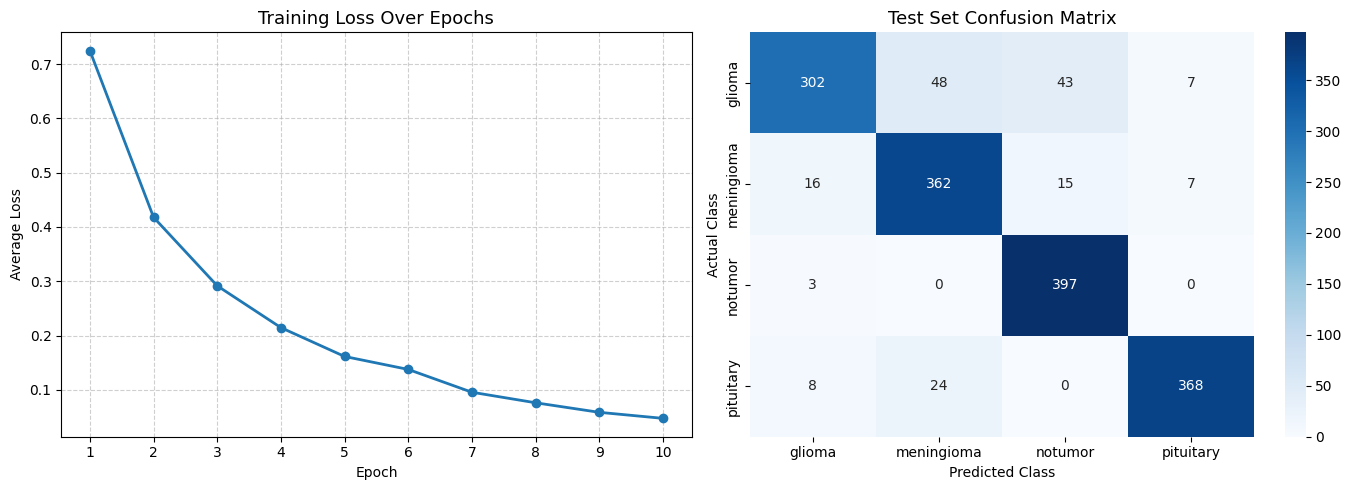


Classification Report:

              precision    recall  f1-score   support

      glioma       0.92      0.76      0.83       400
  meningioma       0.83      0.91      0.87       400
     notumor       0.87      0.99      0.93       400
   pituitary       0.96      0.92      0.94       400

    accuracy                           0.89      1600
   macro avg       0.90      0.89      0.89      1600
weighted avg       0.90      0.89      0.89      1600



In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

epochs_list = list(range(1, 11))
train_losses = [0.7246, 0.4177, 0.2915, 0.2145, 0.1614, 0.1375, 0.0955, 0.0761, 0.0585, 0.0474]

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_list, train_losses, marker='o', color='#1f77b4', linewidth=2)
plt.title('Training Loss Over Epochs', fontsize=13)
plt.xlabel('Epoch')
plt.ylabel('Average Loss')
plt.xticks(epochs_list)
plt.grid(True, linestyle='--', alpha=0.6)

model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

# 3. Plot Confusion Matrix Heatmap
cm = confusion_matrix(all_labels, all_preds)
plt.subplot(1, 2, 2)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=train_data.classes,
            yticklabels=train_data.classes)
plt.title('Test Set Confusion Matrix', fontsize=13)
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.tight_layout()
plt.show()

print("\nClassification Report:\n")
print(classification_report(all_labels, all_preds, target_names=train_data.classes))

Epoch [1/10], Average Loss: 1.2460
Epoch [2/10], Average Loss: 1.0847
Epoch [3/10], Average Loss: 1.1115
Epoch [4/10], Average Loss: 0.9929
Epoch [5/10], Average Loss: 0.9710
Epoch [6/10], Average Loss: 0.8552
Epoch [7/10], Average Loss: 0.8128
Epoch [8/10], Average Loss: 0.7080
Epoch [9/10], Average Loss: 0.6555
Epoch [10/10], Average Loss: 0.6665

LSTM Test Accuracy: 65.00%


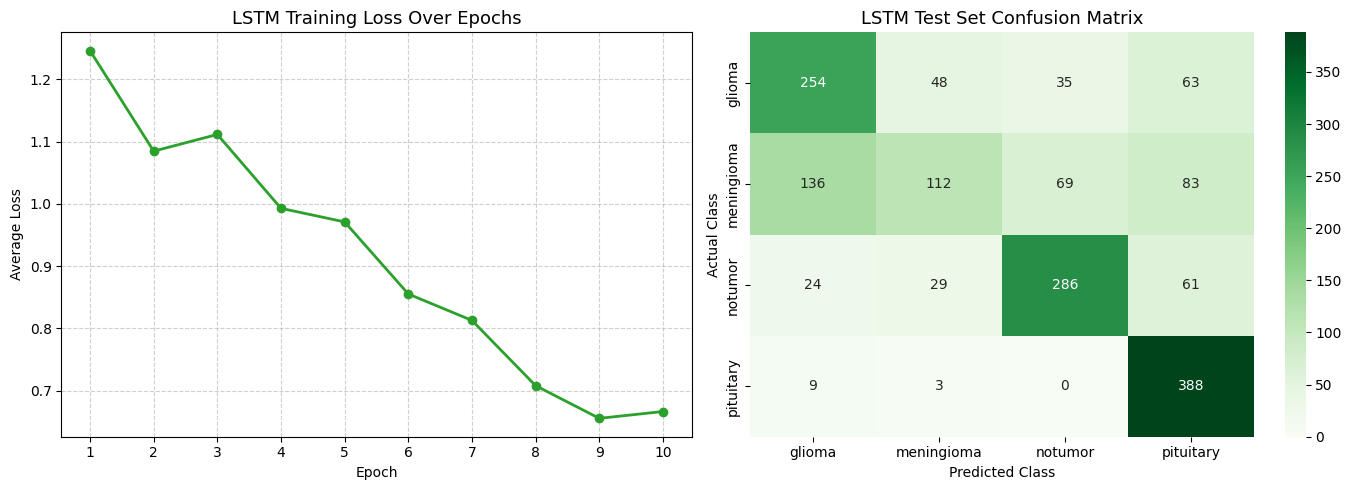


LSTM Classification Report:

              precision    recall  f1-score   support

      glioma       0.60      0.64      0.62       400
  meningioma       0.58      0.28      0.38       400
     notumor       0.73      0.71      0.72       400
   pituitary       0.65      0.97      0.78       400

    accuracy                           0.65      1600
   macro avg       0.64      0.65      0.62      1600
weighted avg       0.64      0.65      0.62      1600



In [9]:
#LSTM
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

class BrainTumorLSTM(nn.Module):
    def __init__(self, input_size=128, hidden_size=128, num_layers=2, num_classes=4):
        super().__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        
        self.lstm = nn.LSTM(
            input_size=input_size, 
            hidden_size=hidden_size, 
            num_layers=num_layers, 
            batch_first=True,
            dropout=0.25
        )
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        x = x.squeeze(1)
        
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        
        out, _ = self.lstm(x, (h0, c0))
        
        out = self.fc(out[:, -1, :])
        return out

lstm_model = BrainTumorLSTM(num_classes=len(train_data.classes)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(lstm_model.parameters(), lr=0.001)

epochs = 10
lstm_losses = []

for epoch in range(epochs):
    lstm_model.train()
    running_loss = 0.0
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = lstm_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        
    avg_loss = running_loss / len(train_loader)
    lstm_losses.append(avg_loss)
    print(f"Epoch [{epoch+1}/{epochs}], Average Loss: {avg_loss:.4f}")

lstm_model.eval()
correct = 0
total = 0
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = lstm_model(images)
        _, predicted = torch.max(outputs, 1)
        
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print(f"\nLSTM Test Accuracy: {100 * correct / total:.2f}%")

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(range(1, epochs + 1), lstm_losses, marker='o', color='#2ca02c', linewidth=2)
plt.title('LSTM Training Loss Over Epochs', fontsize=13)
plt.xlabel('Epoch')
plt.ylabel('Average Loss')
plt.xticks(range(1, epochs + 1))
plt.grid(True, linestyle='--', alpha=0.6)

plt.subplot(1, 2, 2)
cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=train_data.classes,
            yticklabels=train_data.classes)
plt.title('LSTM Test Set Confusion Matrix', fontsize=13)
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.tight_layout()
plt.show()

print("\nLSTM Classification Report:\n")
print(classification_report(all_labels, all_preds, target_names=train_data.classes))

Epoch [1/10], Average Loss: 1.3244
Epoch [2/10], Average Loss: 1.1745
Epoch [3/10], Average Loss: 1.0996
Epoch [4/10], Average Loss: 1.0407
Epoch [5/10], Average Loss: 1.0416
Epoch [6/10], Average Loss: 0.9794
Epoch [7/10], Average Loss: 0.9773
Epoch [8/10], Average Loss: 0.9756
Epoch [9/10], Average Loss: 0.9438
Epoch [10/10], Average Loss: 0.9642

RNN Test Accuracy: 54.31%


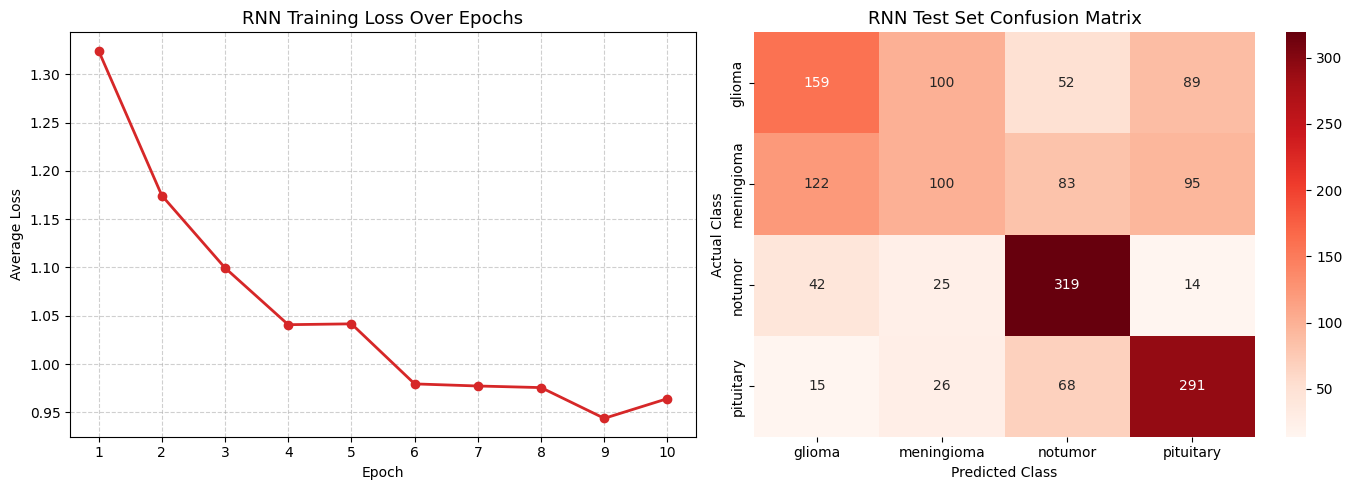


RNN Classification Report:

              precision    recall  f1-score   support

      glioma       0.47      0.40      0.43       400
  meningioma       0.40      0.25      0.31       400
     notumor       0.61      0.80      0.69       400
   pituitary       0.60      0.73      0.65       400

    accuracy                           0.54      1600
   macro avg       0.52      0.54      0.52      1600
weighted avg       0.52      0.54      0.52      1600



In [10]:
#RNN
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

class BrainTumorRNN(nn.Module):
    def __init__(self, input_size=128, hidden_size=128, num_layers=2, num_classes=4):
        super().__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        
        self.rnn = nn.RNN(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            nonlinearity='tanh',
            batch_first=True,
            dropout=0.25
        )
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        x = x.squeeze(1)
        
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        
        out, _ = self.rnn(x, h0)
        
        out = self.fc(out[:, -1, :])
        return out

rnn_model = BrainTumorRNN(num_classes=len(train_data.classes)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(rnn_model.parameters(), lr=0.001)

epochs = 10
rnn_losses = []

for epoch in range(epochs):
    rnn_model.train()
    running_loss = 0.0
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = rnn_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        
        torch.nn.utils.clip_grad_norm_(rnn_model.parameters(), max_norm=1.0)
        optimizer.step()
        
        running_loss += loss.item()
        
    avg_loss = running_loss / len(train_loader)
    rnn_losses.append(avg_loss)
    print(f"Epoch [{epoch+1}/{epochs}], Average Loss: {avg_loss:.4f}")

rnn_model.eval()
correct = 0
total = 0
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = rnn_model(images)
        _, predicted = torch.max(outputs, 1)
        
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print(f"\nRNN Test Accuracy: {100 * correct / total:.2f}%")

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(range(1, epochs + 1), rnn_losses, marker='o', color='#d62728', linewidth=2)
plt.title('RNN Training Loss Over Epochs', fontsize=13)
plt.xlabel('Epoch')
plt.ylabel('Average Loss')
plt.xticks(range(1, epochs + 1))
plt.grid(True, linestyle='--', alpha=0.6)

plt.subplot(1, 2, 2)
cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds',
            xticklabels=train_data.classes,
            yticklabels=train_data.classes)
plt.title('RNN Test Set Confusion Matrix', fontsize=13)
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.tight_layout()
plt.show()

print("\nRNN Classification Report:\n")
print(classification_report(all_labels, all_preds, target_names=train_data.classes))

Using device: cuda
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Converting training images to superpixel graphs...
Converting testing images to superpixel graphs...
Epoch [01/30] | Loss: 0.9466 | Train Acc: 61.59% | Test Acc: 63.12%
Epoch [02/30] | Loss: 0.7974 | Train Acc: 68.55% | Test Acc: 63.00%
Epoch [03/30] | Loss: 0.7229 | Train Acc: 72.00% | Test Acc: 63.69%
Epoch [04/30] | Loss: 0.6907 | Train Acc: 73.36% | Test Acc: 64.25%
Epoch [05/30] | Loss: 0.6778 | Train Acc: 73.79% | Test Acc: 66.62%
Epoch [06/30] | Loss: 0.6563 | Train Acc: 74.89% | Test Acc: 66.69%
Epoch [07/30] | Loss: 0.6359 | Train Acc: 75.12% | Test Acc: 66.12%
Epoch [08/30] | Loss: 0.6070 | Train Acc: 76.54% | Test Acc: 67.88%
Epoch [09/30] | Loss: 0.6065 | Train Acc: 76.16% | Test Acc: 69.94%
Epoch [10/30] | Loss: 0.5756 | Train Acc: 77.95% | Test Acc: 68.38%
Epoch [11/30] | Loss: 0.5694 | Train Acc: 78.27% | Test Acc: 68.56%
Epoch [12/30] | Loss: 0.5618 | Train Acc: 78.21% | Test Acc: 70.38%
Epoch 

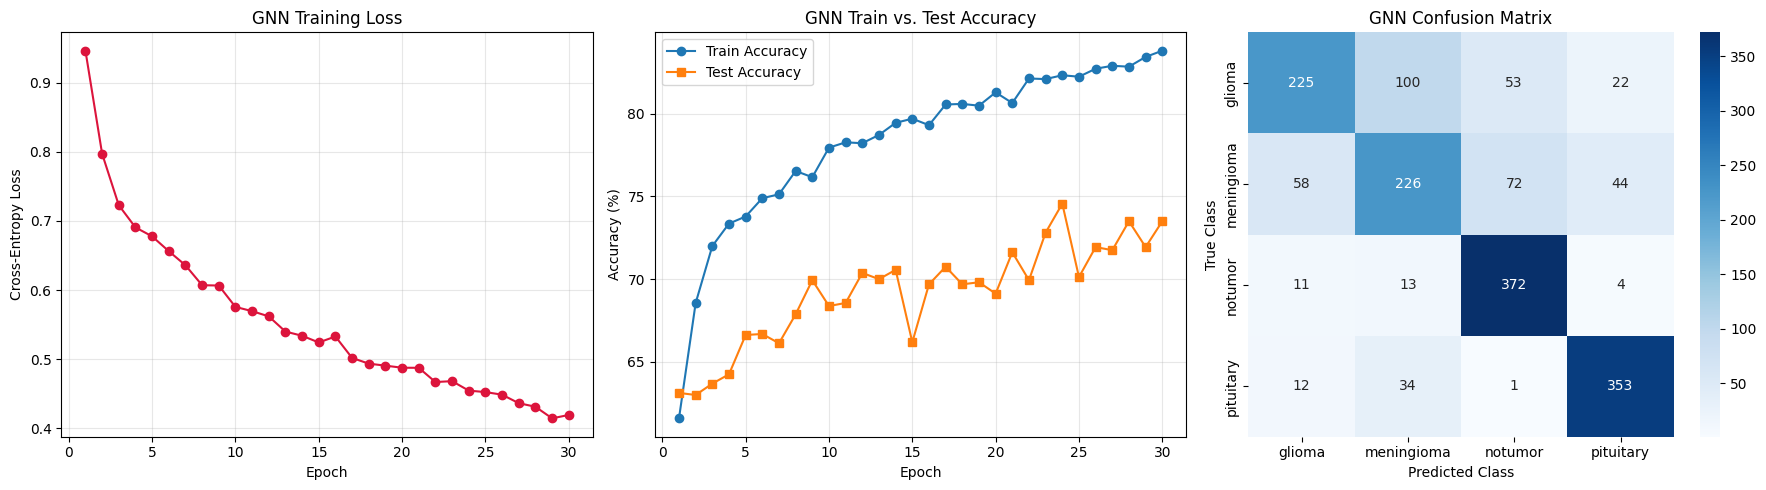

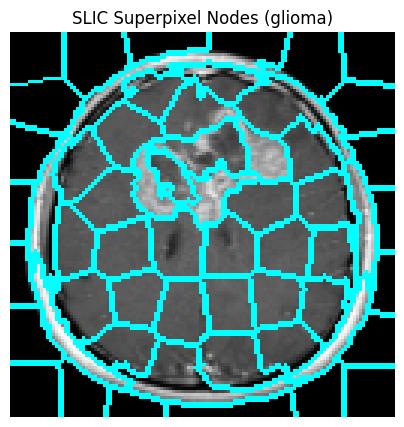

In [9]:
#GNN
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, TensorDataset
from skimage.segmentation import slic
from skimage.segmentation import mark_boundaries
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Setup Device & Automatically Locate Dataset Paths
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

train_dir, test_dir = None, None
for root, dirs, _ in os.walk('/kaggle/input'):
    if 'Training' in dirs and 'Testing' in dirs:
        train_dir = os.path.join(root, 'Training')
        test_dir = os.path.join(root, 'Testing')
        break

if train_dir is None or test_dir is None:
    raise FileNotFoundError("Could not find 'Training' and 'Testing' directories under /kaggle/input")

# Keep values in [0, 1] for SLIC compatibility
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

train_data = datasets.ImageFolder(train_dir, transform=transform)
test_data = datasets.ImageFolder(test_dir, transform=transform)
class_names = train_data.classes
print(f"Classes: {class_names}")

# 2. Image-to-Graph Converter (SLIC Superpixels + Spatial Coordinates)
def images_to_graphs(images, n_segments=64):
    batch_size = images.size(0)
    imgs_np = images.squeeze(1).cpu().numpy()
    # 5 node features: [mean_intensity, std_intensity, relative_area, centroid_y, centroid_x]
    node_feats = np.zeros((batch_size, n_segments, 5), dtype=np.float32)
    adj_batch = np.zeros((batch_size, n_segments, n_segments), dtype=np.float32)
    h, w = imgs_np.shape[1], imgs_np.shape[2]

    for b in range(batch_size):
        img = imgs_np[b]
        segments = slic(img, n_segments=n_segments, compactness=0.2, channel_axis=None, start_label=0)
        num_nodes = min(segments.max() + 1, n_segments)

        for nid in range(num_nodes):
            mask = (segments == nid)
            if np.any(mask):
                px = img[mask]
                ys, xs = np.where(mask)
                node_feats[b, nid] = [
                    px.mean(),
                    px.std(),
                    px.size / img.size,
                    ys.mean() / h,
                    xs.mean() / w
                ]

        adj = np.eye(n_segments, dtype=np.float32)
        for r, c in zip(*np.where(segments[:, :-1] != segments[:, 1:])):
            u, v = segments[r, c], segments[r, c + 1]
            if u < n_segments and v < n_segments:
                adj[u, v] = adj[v, u] = 1.0

        for r, c in zip(*np.where(segments[:-1, :] != segments[1:, :])):
            u, v = segments[r, c], segments[r + 1, c]
            if u < n_segments and v < n_segments:
                adj[u, v] = adj[v, u] = 1.0

        deg = adj.sum(axis=1)
        deg_inv_sqrt = np.zeros_like(deg)
        np.power(deg, -0.5, out=deg_inv_sqrt, where=deg > 0)
        adj_batch[b] = deg_inv_sqrt[:, None] * adj * deg_inv_sqrt[None, :]

    return torch.tensor(node_feats), torch.tensor(adj_batch)

# Precompute graphs once so training runs fast
def build_graph_dataset(image_dataset, desc=""):
    loader = DataLoader(image_dataset, batch_size=64, shuffle=False)
    all_x, all_adj, all_y = [], [], []
    print(f"Converting {desc} images to superpixel graphs...")
    for imgs, labels in loader:
        x, adj = images_to_graphs(imgs, n_segments=64)
        all_x.append(x)
        all_adj.append(adj)
        all_y.append(labels)
    return TensorDataset(torch.cat(all_x), torch.cat(all_adj), torch.cat(all_y))

train_graph_ds = build_graph_dataset(train_data, "training")
test_graph_ds = build_graph_dataset(test_data, "testing")

train_loader = DataLoader(train_graph_ds, batch_size=32, shuffle=True)
test_loader = DataLoader(test_graph_ds, batch_size=32, shuffle=False)

# 3. Define GCN Layer & BrainTumorGNN Model
class GCNLayer(nn.Module):
    def __init__(self, in_features, out_features):
        super().__init__()
        self.linear = nn.Linear(in_features, out_features)
        self.bn = nn.BatchNorm1d(out_features)

    def forward(self, x, adj):
        out = torch.bmm(adj, self.linear(x))
        # BatchNorm1d expects (batch, features, nodes)
        out = self.bn(out.transpose(1, 2)).transpose(1, 2)
        return out

class BrainTumorGNN(nn.Module):
    def __init__(self, in_features=5, hidden_dim=64, num_classes=4):
        super().__init__()
        self.gcn1 = GCNLayer(in_features, hidden_dim)
        self.gcn2 = GCNLayer(hidden_dim, hidden_dim * 2)
        self.gcn3 = GCNLayer(hidden_dim * 2, hidden_dim * 2)
        self.dropout = nn.Dropout(0.3)
        # Concatenate mean + max pooling for richer graph-level representation
        self.fc1 = nn.Linear(hidden_dim * 4, 64)
        self.fc2 = nn.Linear(64, num_classes)

    def forward(self, x, adj):
        x = F.relu(self.gcn1(x, adj))
        x = F.relu(self.gcn2(x, adj))
        x = F.relu(self.gcn3(x, adj))
        x_mean = x.mean(dim=1)
        x_max = x.max(dim=1).values
        x = torch.cat([x_mean, x_max], dim=1)
        x = self.dropout(F.relu(self.fc1(x)))
        return self.fc2(x)

# 4. Train & Evaluate the GNN Model
gnn_model = BrainTumorGNN(in_features=5, num_classes=len(class_names)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(gnn_model.parameters(), lr=0.001, weight_decay=1e-4)

epochs = 30
train_losses, train_accs, test_accs = [], [], []

for epoch in range(epochs):
    gnn_model.train()
    running_loss, correct, total = 0.0, 0, 0

    for node_feats, adj, labels in train_loader:
        node_feats, adj, labels = node_feats.to(device), adj.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = gnn_model(node_feats, adj)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total
    train_losses.append(train_loss)
    train_accs.append(train_acc)

    # Evaluate on test set each epoch
    gnn_model.eval()
    test_correct, test_total = 0, 0
    with torch.no_grad():
        for node_feats, adj, labels in test_loader:
            node_feats, adj, labels = node_feats.to(device), adj.to(device), labels.to(device)
            outputs = gnn_model(node_feats, adj)
            test_correct += (outputs.argmax(dim=1) == labels).sum().item()
            test_total += labels.size(0)

    test_acc = test_correct / test_total
    test_accs.append(test_acc)
    print(f"Epoch [{epoch+1:02d}/{epochs}] | Loss: {train_loss:.4f} | Train Acc: {train_acc*100:.2f}% | Test Acc: {test_acc*100:.2f}%")

# 5. Final Accuracy, Classification Report & Graphs
gnn_model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for node_feats, adj, labels in test_loader:
        node_feats, adj = node_feats.to(device), adj.to(device)
        outputs = gnn_model(node_feats, adj)
        all_preds.extend(outputs.argmax(dim=1).cpu().numpy())
        all_labels.extend(labels.numpy())

final_acc = accuracy_score(all_labels, all_preds)
print(f"\nFinal Test Accuracy: {final_acc * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(all_labels, all_preds, target_names=class_names))

# Plot 1 & 2: Training Loss & Accuracy Curves
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(range(1, epochs + 1), train_losses, marker='o', color='crimson')
axes[0].set_title('GNN Training Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].grid(True, alpha=0.3)

axes[1].plot(range(1, epochs + 1), [a * 100 for a in train_accs], label='Train Accuracy', marker='o')
axes[1].plot(range(1, epochs + 1), [a * 100 for a in test_accs], label='Test Accuracy', marker='s')
axes[1].set_title('GNN Train vs. Test Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Plot 3: Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=axes[2])
axes[2].set_title('GNN Confusion Matrix')
axes[2].set_xlabel('Predicted Class')
axes[2].set_ylabel('True Class')

plt.tight_layout()
plt.show()

# Plot 4: Sample Superpixel Graph Visualization
sample_img, sample_label = test_data[0]
img_np = sample_img.squeeze(0).numpy()
segs = slic(img_np, n_segments=64, compactness=0.2, channel_axis=None, start_label=0)

plt.figure(figsize=(5, 5))
plt.imshow(mark_boundaries(img_np, segs, color=(0, 1, 1)))
plt.title(f"SLIC Superpixel Nodes ({class_names[sample_label]})")
plt.axis('off')
plt.show()

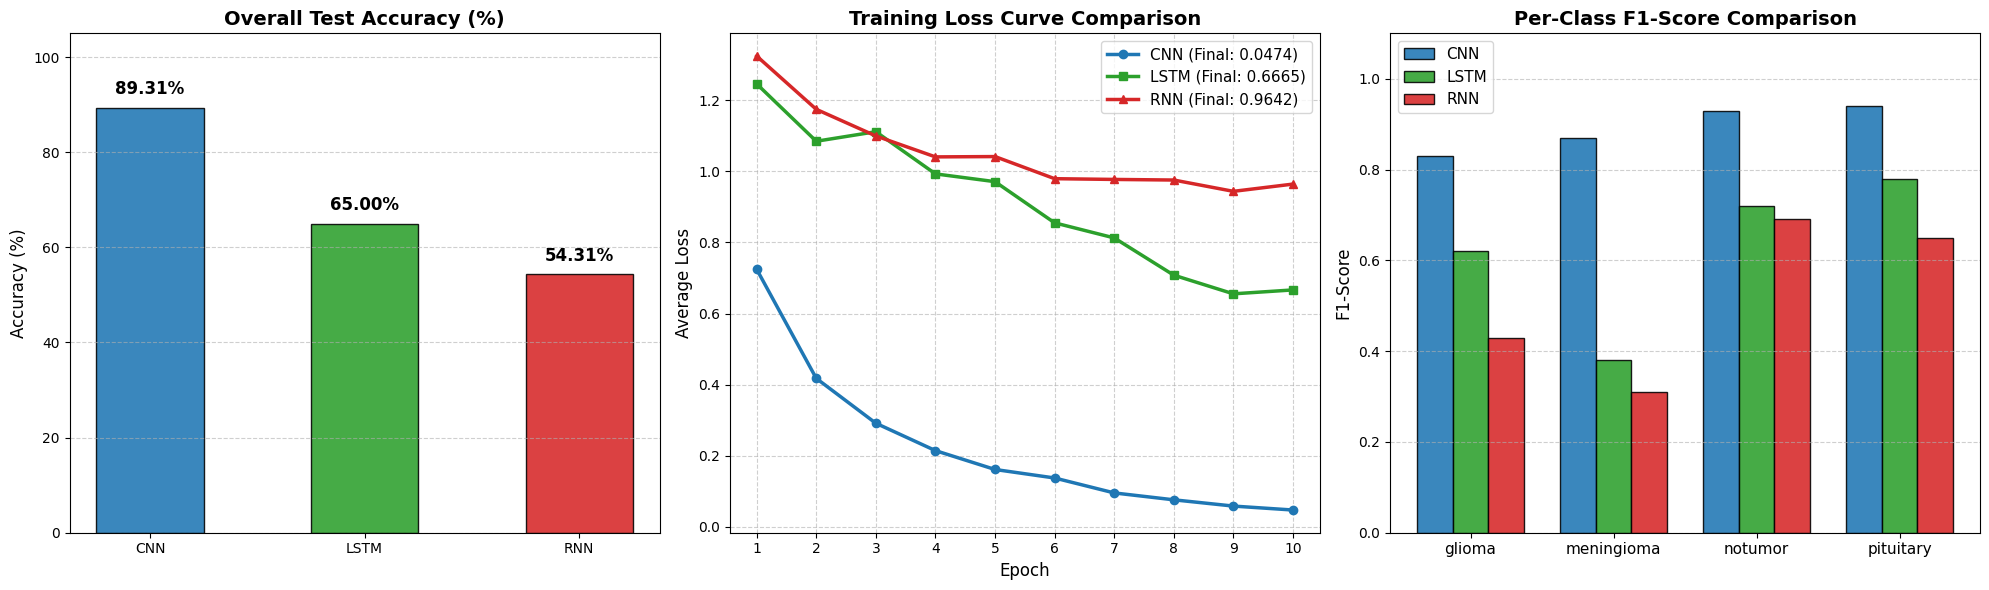

In [11]:
import matplotlib.pyplot as plt
import numpy as np

models = ['CNN', 'LSTM', 'RNN']
test_accuracies = [89.31, 65.00, 54.31]
epochs = list(range(1, 11))

cnn_losses = [0.7246, 0.4177, 0.2915, 0.2145, 0.1614, 0.1375, 0.0955, 0.0761, 0.0585, 0.0474]
lstm_losses = [1.2460, 1.0847, 1.1115, 0.9929, 0.9710, 0.8552, 0.8128, 0.7080, 0.6555, 0.6665]
rnn_losses = [1.3244, 1.1745, 1.0996, 1.0407, 1.0416, 0.9794, 0.9773, 0.9756, 0.9438, 0.9642]

classes = ['glioma', 'meningioma', 'notumor', 'pituitary']
cnn_f1 = [0.83, 0.87, 0.93, 0.94]
lstm_f1 = [0.62, 0.38, 0.72, 0.78]
rnn_f1 = [0.43, 0.31, 0.69, 0.65]

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
colors = ['#1f77b4', '#2ca02c', '#d62728']

bars = axes[0].bar(models, test_accuracies, color=colors, width=0.5, edgecolor='black', alpha=0.88)
axes[0].set_title('Overall Test Accuracy (%)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Accuracy (%)', fontsize=12)
axes[0].set_ylim(0, 105)
axes[0].grid(axis='y', linestyle='--', alpha=0.6)

for bar in bars:
    height = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, height + 2, f'{height:.2f}%',
                 ha='center', va='bottom', fontsize=12, fontweight='bold')

axes[1].plot(epochs, cnn_losses, marker='o', color=colors[0], linewidth=2.5, label='CNN (Final: 0.0474)')
axes[1].plot(epochs, lstm_losses, marker='s', color=colors[1], linewidth=2.5, label='LSTM (Final: 0.6665)')
axes[1].plot(epochs, rnn_losses, marker='^', color=colors[2], linewidth=2.5, label='RNN (Final: 0.9642)')
axes[1].set_title('Training Loss Curve Comparison', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('Average Loss', fontsize=12)
axes[1].set_xticks(epochs)
axes[1].legend(fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.6)

x = np.arange(len(classes))
width = 0.25

axes[2].bar(x - width, cnn_f1, width, label='CNN', color=colors[0], edgecolor='black', alpha=0.88)
axes[2].bar(x, lstm_f1, width, label='LSTM', color=colors[1], edgecolor='black', alpha=0.88)
axes[2].bar(x + width, rnn_f1, width, label='RNN', color=colors[2], edgecolor='black', alpha=0.88)

axes[2].set_title('Per-Class F1-Score Comparison', fontsize=14, fontweight='bold')
axes[2].set_ylabel('F1-Score', fontsize=12)
axes[2].set_xticks(x)
axes[2].set_xticklabels(classes, fontsize=11)
axes[2].set_ylim(0, 1.1)
axes[2].legend(fontsize=11)
axes[2].grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

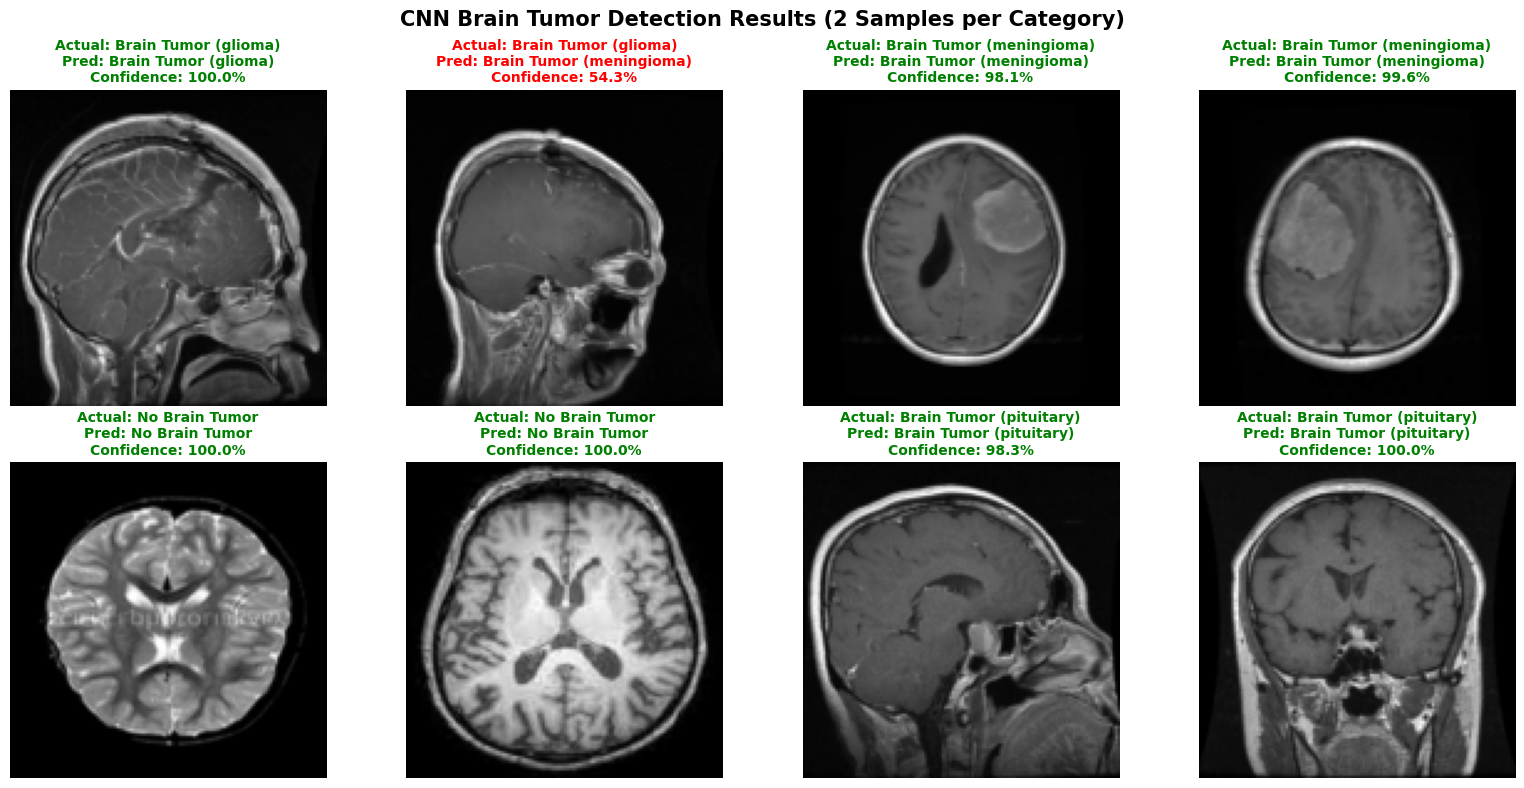

In [12]:
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import random

class_indices = {i: [] for i in range(len(test_data.classes))}
for idx, (_, label) in enumerate(test_data.samples):
    class_indices[label].append(idx)

selected_indices = []
for cls_idx in range(len(test_data.classes)):
    selected_indices.extend(random.sample(class_indices[cls_idx], 2))

model.eval()
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

with torch.no_grad():
    for i, idx in enumerate(selected_indices):
        img_tensor, actual_label_idx = test_data[idx]
        input_batch = img_tensor.unsqueeze(0).to(device)
        
        outputs = model(input_batch)
        probs = F.softmax(outputs, dim=1)
        confidence, pred_idx = torch.max(probs, 1)
        
        actual_class = test_data.classes[actual_label_idx]
        pred_class = test_data.classes[pred_idx.item()]
        conf_pct = confidence.item() * 100
        
        actual_status = "No Brain Tumor" if actual_class == "notumor" else f"Brain Tumor ({actual_class})"
        pred_status = "No Brain Tumor" if pred_class == "notumor" else f"Brain Tumor ({pred_class})"
        
        img_display = img_tensor.squeeze().cpu().numpy() * 0.5 + 0.5
        
        axes[i].imshow(img_display, cmap='gray')
        axes[i].axis('off')
        
        title_color = 'green' if actual_class == pred_class else 'red'
        axes[i].set_title(
            f"Actual: {actual_status}\nPred: {pred_status}\nConfidence: {conf_pct:.1f}%",
            fontsize=10,
            fontweight='bold',
            color=title_color
        )

plt.suptitle("CNN Brain Tumor Detection Results (2 Samples per Category)", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()